# Customer Churn: Cleaning, EDA & Data Preparation (Phase 2)


# Import Libraries

In [30]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
import math
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


RANDOM_STATE = 42
USE_ORDINAL_CONTRACT = True     # False = One-Hot for contract_type
ALPHA = 0.05                    # significance level
MIN_STRENGTH = 0.02             # minimum relationship strength to keep a feature

# Helper Functions

In [31]:
def data_info(data):
    """Summary of each column: dtype, top values, unique count, nulls, null %"""
    info_df = pd.DataFrame({
        "Name": data.columns,
        "Data_Type": [data[c].dtype for c in data.columns],
        "Top_10_Values": [data[c].value_counts().head(10).index.to_list() for c in data.columns],
        "Nunique": [data[c].nunique() for c in data.columns],
        "Nulls": [data[c].isnull().sum() for c in data.columns],
        "Nulls_%": [round(data[c].isnull().mean() * 100, 2) for c in data.columns],
    })
    print(f"Shape: {data.shape} | Duplicated rows: {data.duplicated().sum()}")
    return info_df


def count_outliers(data, cols, factor=1.5, plot=False):
    """Counts outliers per column using the IQR method (does not remove them)."""
    rows = []
    for col in cols:
        q1, q3 = data[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        low, high = q1 - factor * iqr, q3 + factor * iqr
        mask = (data[col] < low) | (data[col] > high)
        rows.append({"feature": col, "n_outliers": int(mask.sum()),
                     "outliers_%": round(mask.mean() * 100, 2),
                     "lower_bound": round(low, 2), "upper_bound": round(high, 2),
                     "min": data[col].min(), "max": data[col].max()})
    if plot:
        fig, axes = plt.subplots(1, len(cols), figsize=(5 * len(cols), 4))
        axes = np.atleast_1d(axes)
        for ax, col in zip(axes, cols):
            sns.boxplot(y=data[col], ax=ax, color="#4C9F70")
            ax.set_title(col)
        plt.tight_layout()
        plt.show()
    return pd.DataFrame(rows)


def cramers_v_and_p(x, y):
    """Cramer's V (strength 0-1) and chi-square p-value between a categorical column and the target."""
    table = pd.crosstab(x, y)
    chi2, p, _, _ = chi2_contingency(table)
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1))), p

# Data Overview

In [32]:
df = pd.read_csv("unified_customers.csv")
print(df.shape)
df.info()
display(df.head())
display(df.describe().round(2))
display(data_info(df))          # summary BEFORE cleaning

(7043, 25)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 25 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         7043 non-null   object 
 1   gender              7043 non-null   object 
 2   senior_citizen      7043 non-null   int64  
 3   partner             7043 non-null   object 
 4   dependents          7043 non-null   object 
 5   tenure_months       7043 non-null   int64  
 6   tenure_group        7043 non-null   object 
 7   phone_service       7043 non-null   object 
 8   multiple_lines      7043 non-null   object 
 9   internet_service    7043 non-null   object 
 10  online_security     7043 non-null   object 
 11  online_backup       7043 non-null   object 
 12  device_protection   7043 non-null   object 
 13  streaming_tv        7043 non-null   object 
 14  streaming_movies    7043 non-null   object 
 15  contract_type       7043 non-null   object 


,customer_id,gender,senior_citizen,partner,dependents,tenure_months,tenure_group,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,streaming_tv,streaming_movies,contract_type,tech_support,payment_method,paperless_billing,monthly_charges,total_charges,num_addon_services,avg_monthly_spend,auto_pay,churn
0,0002-ORFBO,Female,0,Yes,Yes,9,0-12,Yes,No,DSL,No,Yes,No,Yes,No,One year,Yes,Mailed check,Yes,65.6,593.30,3,65.92,0,0
1,0003-MKNFE,Male,0,No,No,9,0-12,Yes,Yes,DSL,No,No,No,No,Yes,Month-to-month,No,Mailed check,No,59.9,542.40,1,60.27,0,0
2,0004-TLHLJ,Male,0,No,No,4,0-12,Yes,No,Fiber optic,No,No,Yes,No,No,Month-to-month,No,Electronic check,Yes,73.9,280.85,1,70.21,0,1
3,0011-IGKFF,Male,1,Yes,No,13,13-24,Yes,No,Fiber optic,No,Yes,Yes,Yes,Yes,Month-to-month,No,Electronic check,Yes,98.0,1237.85,4,95.22,0,1
4,0013-EXCHZ,Female,1,Yes,No,3,0-12,Yes,No,Fiber optic,No,No,No,Yes,No,Month-to-month,Yes,Mailed check,Yes,83.9,267.40,2,89.13,0,1


,senior_citizen,tenure_months,monthly_charges,total_charges,num_addon_services,avg_monthly_spend,auto_pay,churn
count,7043.00,7043.00,7043.00,7032.00,7043.00,7032.00,7043.00,7043.00
mean,0.16,32.37,64.76,2283.30,2.04,64.80,0.44,0.27
std,0.37,24.56,30.09,2266.77,1.85,30.19,0.50,0.44
min,0.00,0.00,18.25,18.80,0.00,13.78,0.00,0.00
25%,0.00,9.00,35.50,401.45,0.00,36.18,0.00,0.00
50%,0.00,29.00,70.35,1397.48,2.00,70.38,0.00,0.00
75%,0.00,55.00,89.85,3794.74,3.00,90.18,1.00,1.00
max,1.00,72.00,118.75,8684.80,6.00,121.40,1.00,1.00


Shape: (7043, 25) | Duplicated rows: 0


,Name,Data_Type,Top_10_Values,Nunique,Nulls,Nulls_%
0,customer_id,object,"[9995-HOTOH, 0002-ORFBO, 0003-MKNFE, 9970-QBCD...",7043,0,0.00
1,gender,object,"[Male, Female]",2,0,0.00
2,senior_citizen,int64,"[0, 1]",2,0,0.00
3,partner,object,"[No, Yes]",2,0,0.00
4,dependents,object,"[No, Yes]",2,0,0.00
5,tenure_months,int64,"[1, 72, 2, 3, 4, 71, 5, 7, 8, 9]",73,0,0.00
6,tenure_group,object,"[49-72, 0-12, 25-48, 13-24]",4,0,0.00
7,phone_service,object,"[Yes, No]",2,0,0.00
8,multiple_lines,object,"[No, Yes, No phone service]",3,0,0.00
9,internet_service,object,"[Fiber optic, DSL, No]",3,0,0.00


# Preprocessing (Nulls, Duplicates, Outliers)

### Column names and text values

In [33]:
print(df.columns.tolist())        # already snake_case from the SQL phase

obj_cols = df.select_dtypes(include="object").columns.drop("customer_id")
for c in obj_cols:
    df[c] = df[c].str.strip()

['customer_id', 'gender', 'senior_citizen', 'partner', 'dependents', 'tenure_months', 'tenure_group', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'streaming_tv', 'streaming_movies', 'contract_type', 'tech_support', 'payment_method', 'paperless_billing', 'monthly_charges', 'total_charges', 'num_addon_services', 'avg_monthly_spend', 'auto_pay', 'churn']


### Nulls

In [34]:
nulls = df.isnull().sum()
print(nulls[nulls > 0])
display(df[df["total_charges"].isnull()][["customer_id", "tenure_months", "monthly_charges", "churn"]])

total_charges        11
avg_monthly_spend    11
dtype: int64


,customer_id,tenure_months,monthly_charges,churn
945,1371-DWPAZ,0,56.05,0
1731,2520-SGTTA,0,20.00,0
1906,2775-SEFEE,0,61.90,0
2025,2923-ARZLG,0,19.70,0
2176,3115-CZMZD,0,20.25,0
2250,3213-VVOLG,0,25.35,0
2855,4075-WKNIU,0,73.35,0
3052,4367-NUYAO,0,25.75,0
3118,4472-LVYGI,0,52.55,0
4054,5709-LVOEQ,0,80.85,0


In [35]:
# The nulls are new customers (tenure = 0) who were not billed yet, so they are not random missing values
df["total_charges"] = df["total_charges"].fillna(0)
df["avg_monthly_spend"] = df["avg_monthly_spend"].fillna(df["monthly_charges"])
print("Nulls left:", df.isnull().sum().sum())

Nulls left: 0


**Decision:** the 11 nulls belong to customers with `tenure_months = 0`. `total_charges` = 0 (nothing paid yet) and `avg_monthly_spend` = their `monthly_charges`.

### Duplicates

In [36]:
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated customer_id:", df["customer_id"].duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

Duplicated rows: 0
Duplicated customer_id: 0


### Inconsistent values

In [37]:
service_cols = ["multiple_lines", "online_security", "online_backup",
                "device_protection", "streaming_tv", "streaming_movies", "tech_support"]

# "No internet service" / "No phone service" both mean the customer does not have the service
for c in service_cols:
    df[c] = df[c].replace({"No internet service": "No", "No phone service": "No"})
    print(c, df[c].unique())

print("churn values:", df["churn"].unique())
display(data_info(df))          # summary AFTER cleaning

multiple_lines ['No' 'Yes']
online_security ['No' 'Yes']
online_backup ['Yes' 'No']
device_protection ['No' 'Yes']
streaming_tv ['Yes' 'No']
streaming_movies ['No' 'Yes']
tech_support ['Yes' 'No']
churn values: [0 1]
Shape: (7043, 25) | Duplicated rows: 0


,Name,Data_Type,Top_10_Values,Nunique,Nulls,Nulls_%
0,customer_id,object,"[9995-HOTOH, 0002-ORFBO, 0003-MKNFE, 9970-QBCD...",7043,0,0.0
1,gender,object,"[Male, Female]",2,0,0.0
2,senior_citizen,int64,"[0, 1]",2,0,0.0
3,partner,object,"[No, Yes]",2,0,0.0
4,dependents,object,"[No, Yes]",2,0,0.0
5,tenure_months,int64,"[1, 72, 2, 3, 4, 71, 5, 7, 8, 9]",73,0,0.0
6,tenure_group,object,"[49-72, 0-12, 25-48, 13-24]",4,0,0.0
7,phone_service,object,"[Yes, No]",2,0,0.0
8,multiple_lines,object,"[No, Yes]",2,0,0.0
9,internet_service,object,"[Fiber optic, DSL, No]",3,0,0.0


### Outliers (IQR, counted but not removed)

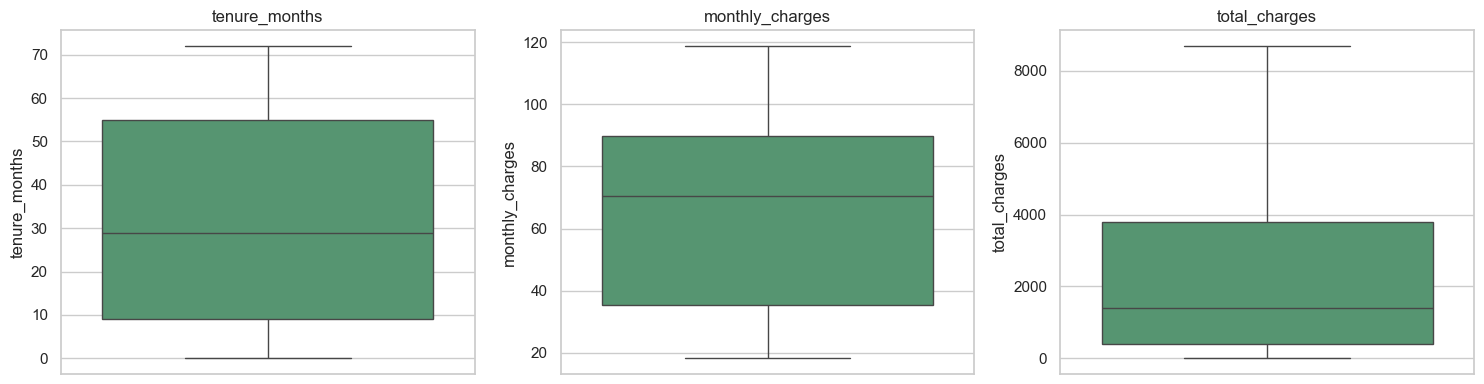

,feature,n_outliers,outliers_%,lower_bound,upper_bound,min,max
0,tenure_months,0,0.0,-60.00,124.00,0.00,72.00
1,monthly_charges,0,0.0,-46.02,171.38,18.25,118.75
2,total_charges,0,0.0,-4683.52,8868.67,0.00,8684.80


In [38]:
display(count_outliers(df, ["tenure_months", "monthly_charges", "total_charges"], plot=True))

**Decision:** outliers are only counted. High values are real bills / long tenures, not data errors, so nothing is removed.

# Analysis and Visualizations to get Information about the data

Overall churn rate: 26.54%
churn
0    5174
1    1869
Name: count, dtype: int64


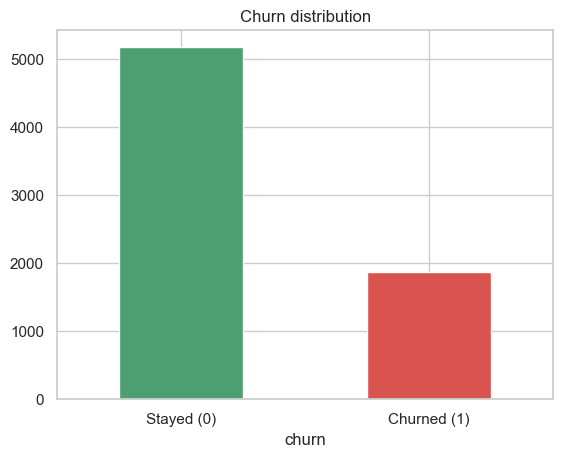

In [39]:
churn_rate = df["churn"].mean() * 100
print(f"Overall churn rate: {churn_rate:.2f}%")
print(df["churn"].value_counts())

df["churn"].value_counts().sort_index().plot(kind="bar", color=["#4C9F70", "#D9534F"])
plt.xticks([0, 1], ["Stayed (0)", "Churned (1)"], rotation=0)
plt.title("Churn distribution")
plt.show()

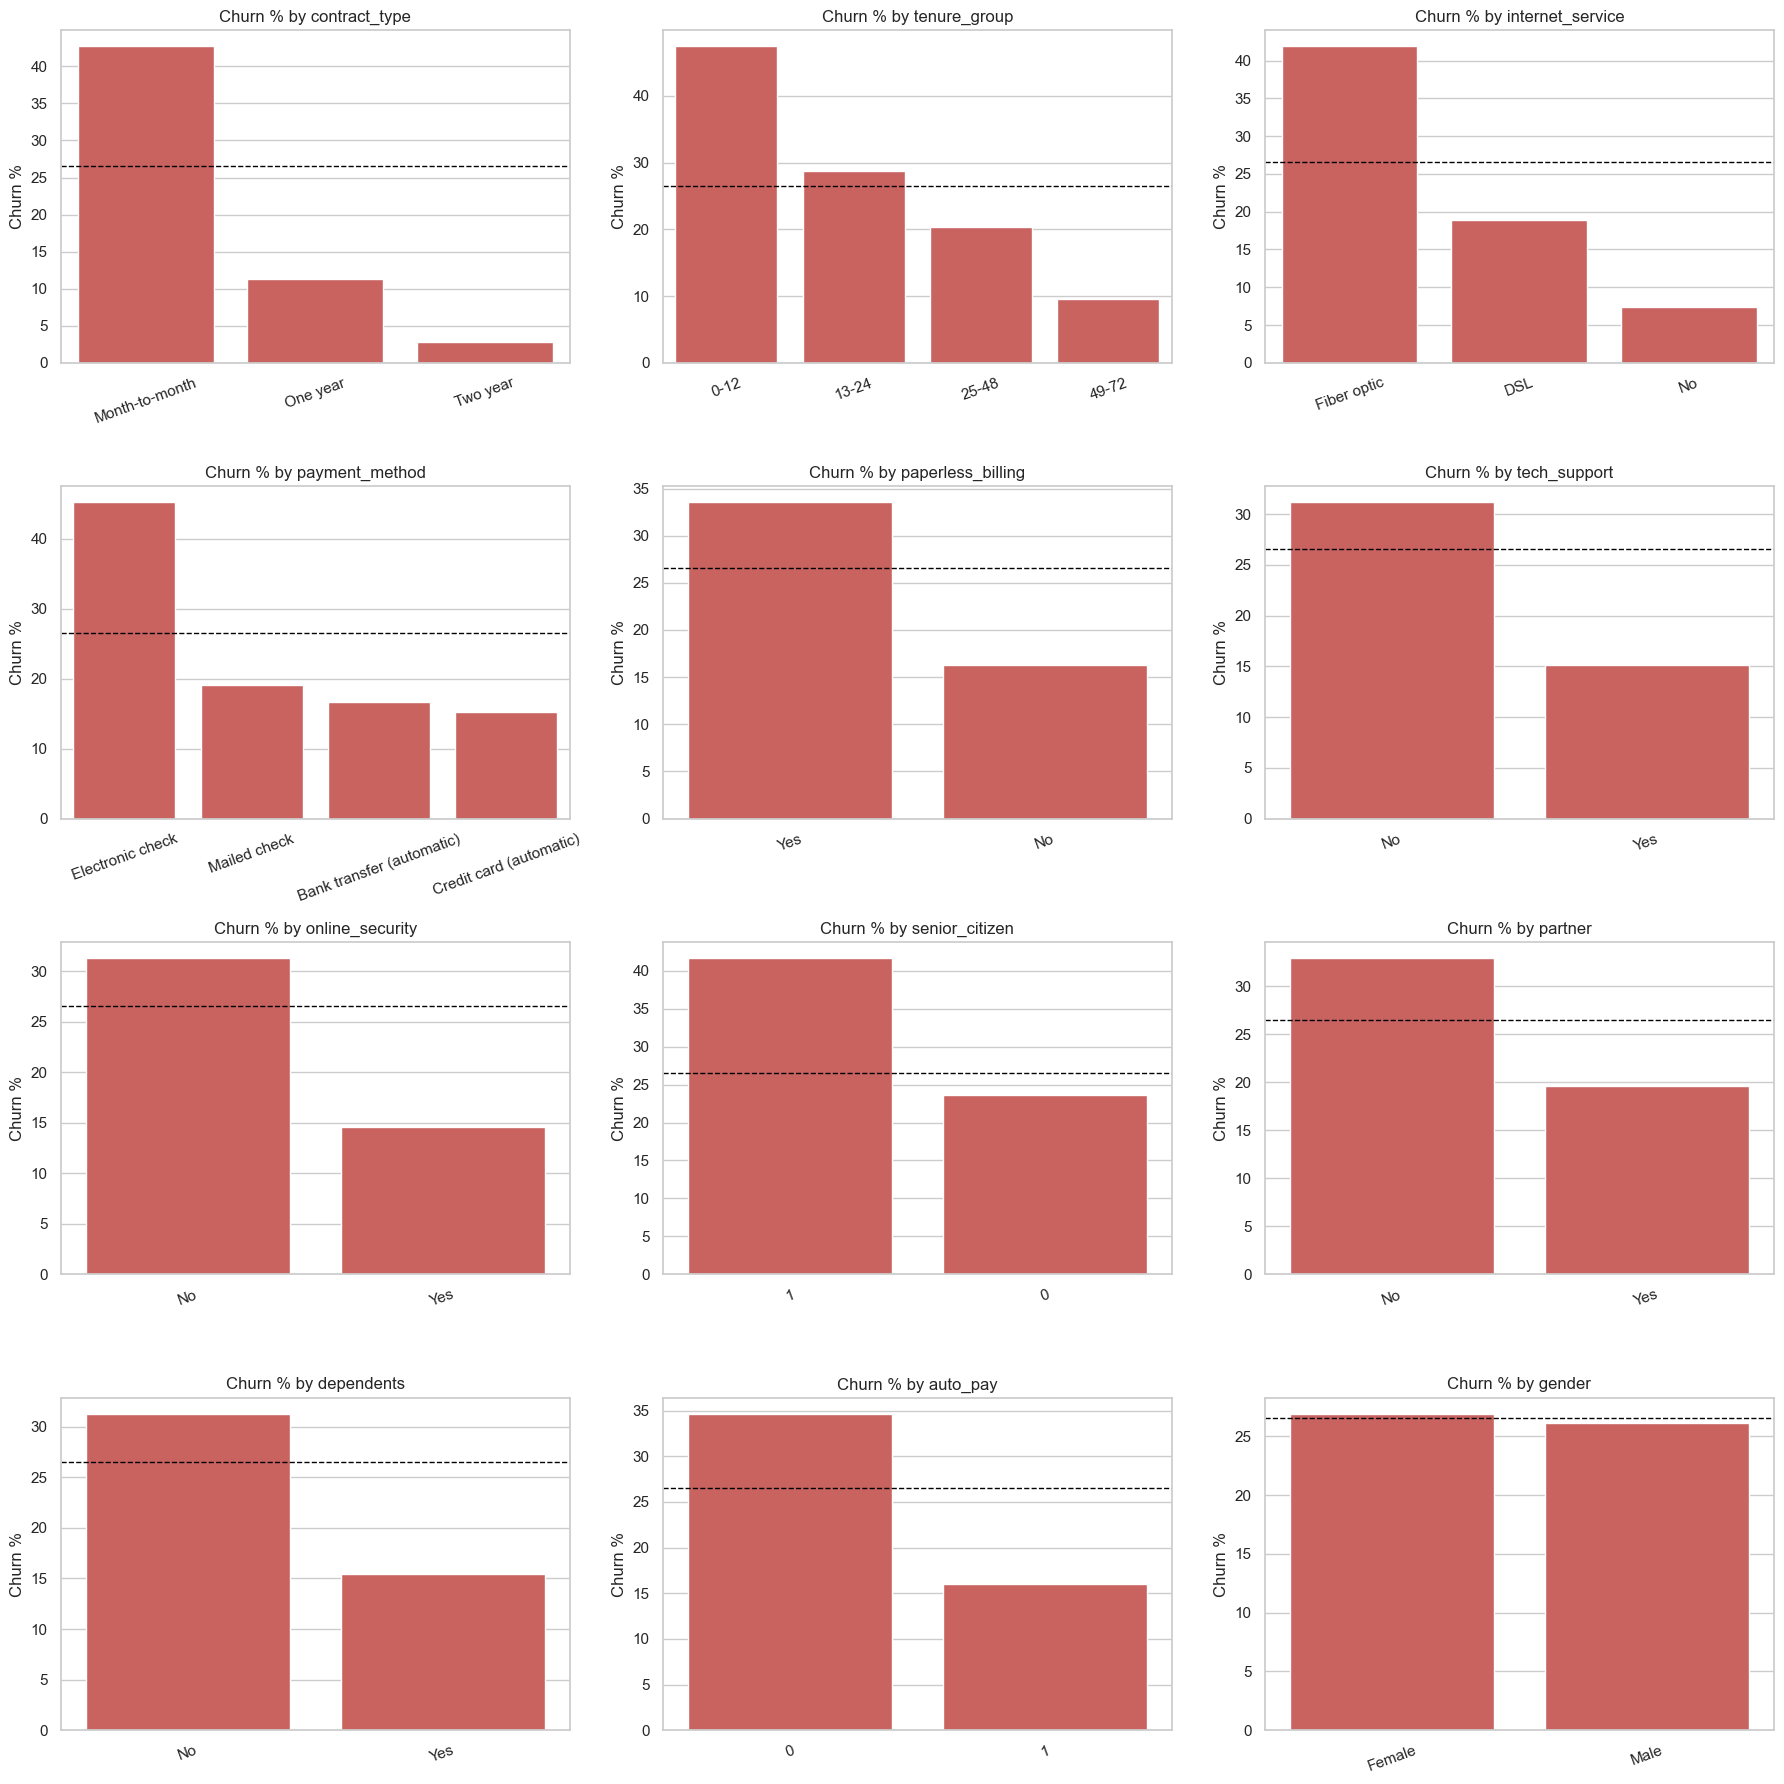

In [40]:
cat_cols = ["contract_type", "tenure_group", "internet_service", "payment_method",
            "paperless_billing", "tech_support", "online_security", "senior_citizen",
            "partner", "dependents", "auto_pay", "gender"]

fig, axes = plt.subplots(4, 3, figsize=(18, 18))
for ax, col in zip(axes.flatten(), cat_cols):
    rate = df.groupby(col)["churn"].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#D9534F")
    ax.axhline(churn_rate, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"Churn % by {col}")
    ax.set_ylabel("Churn %")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

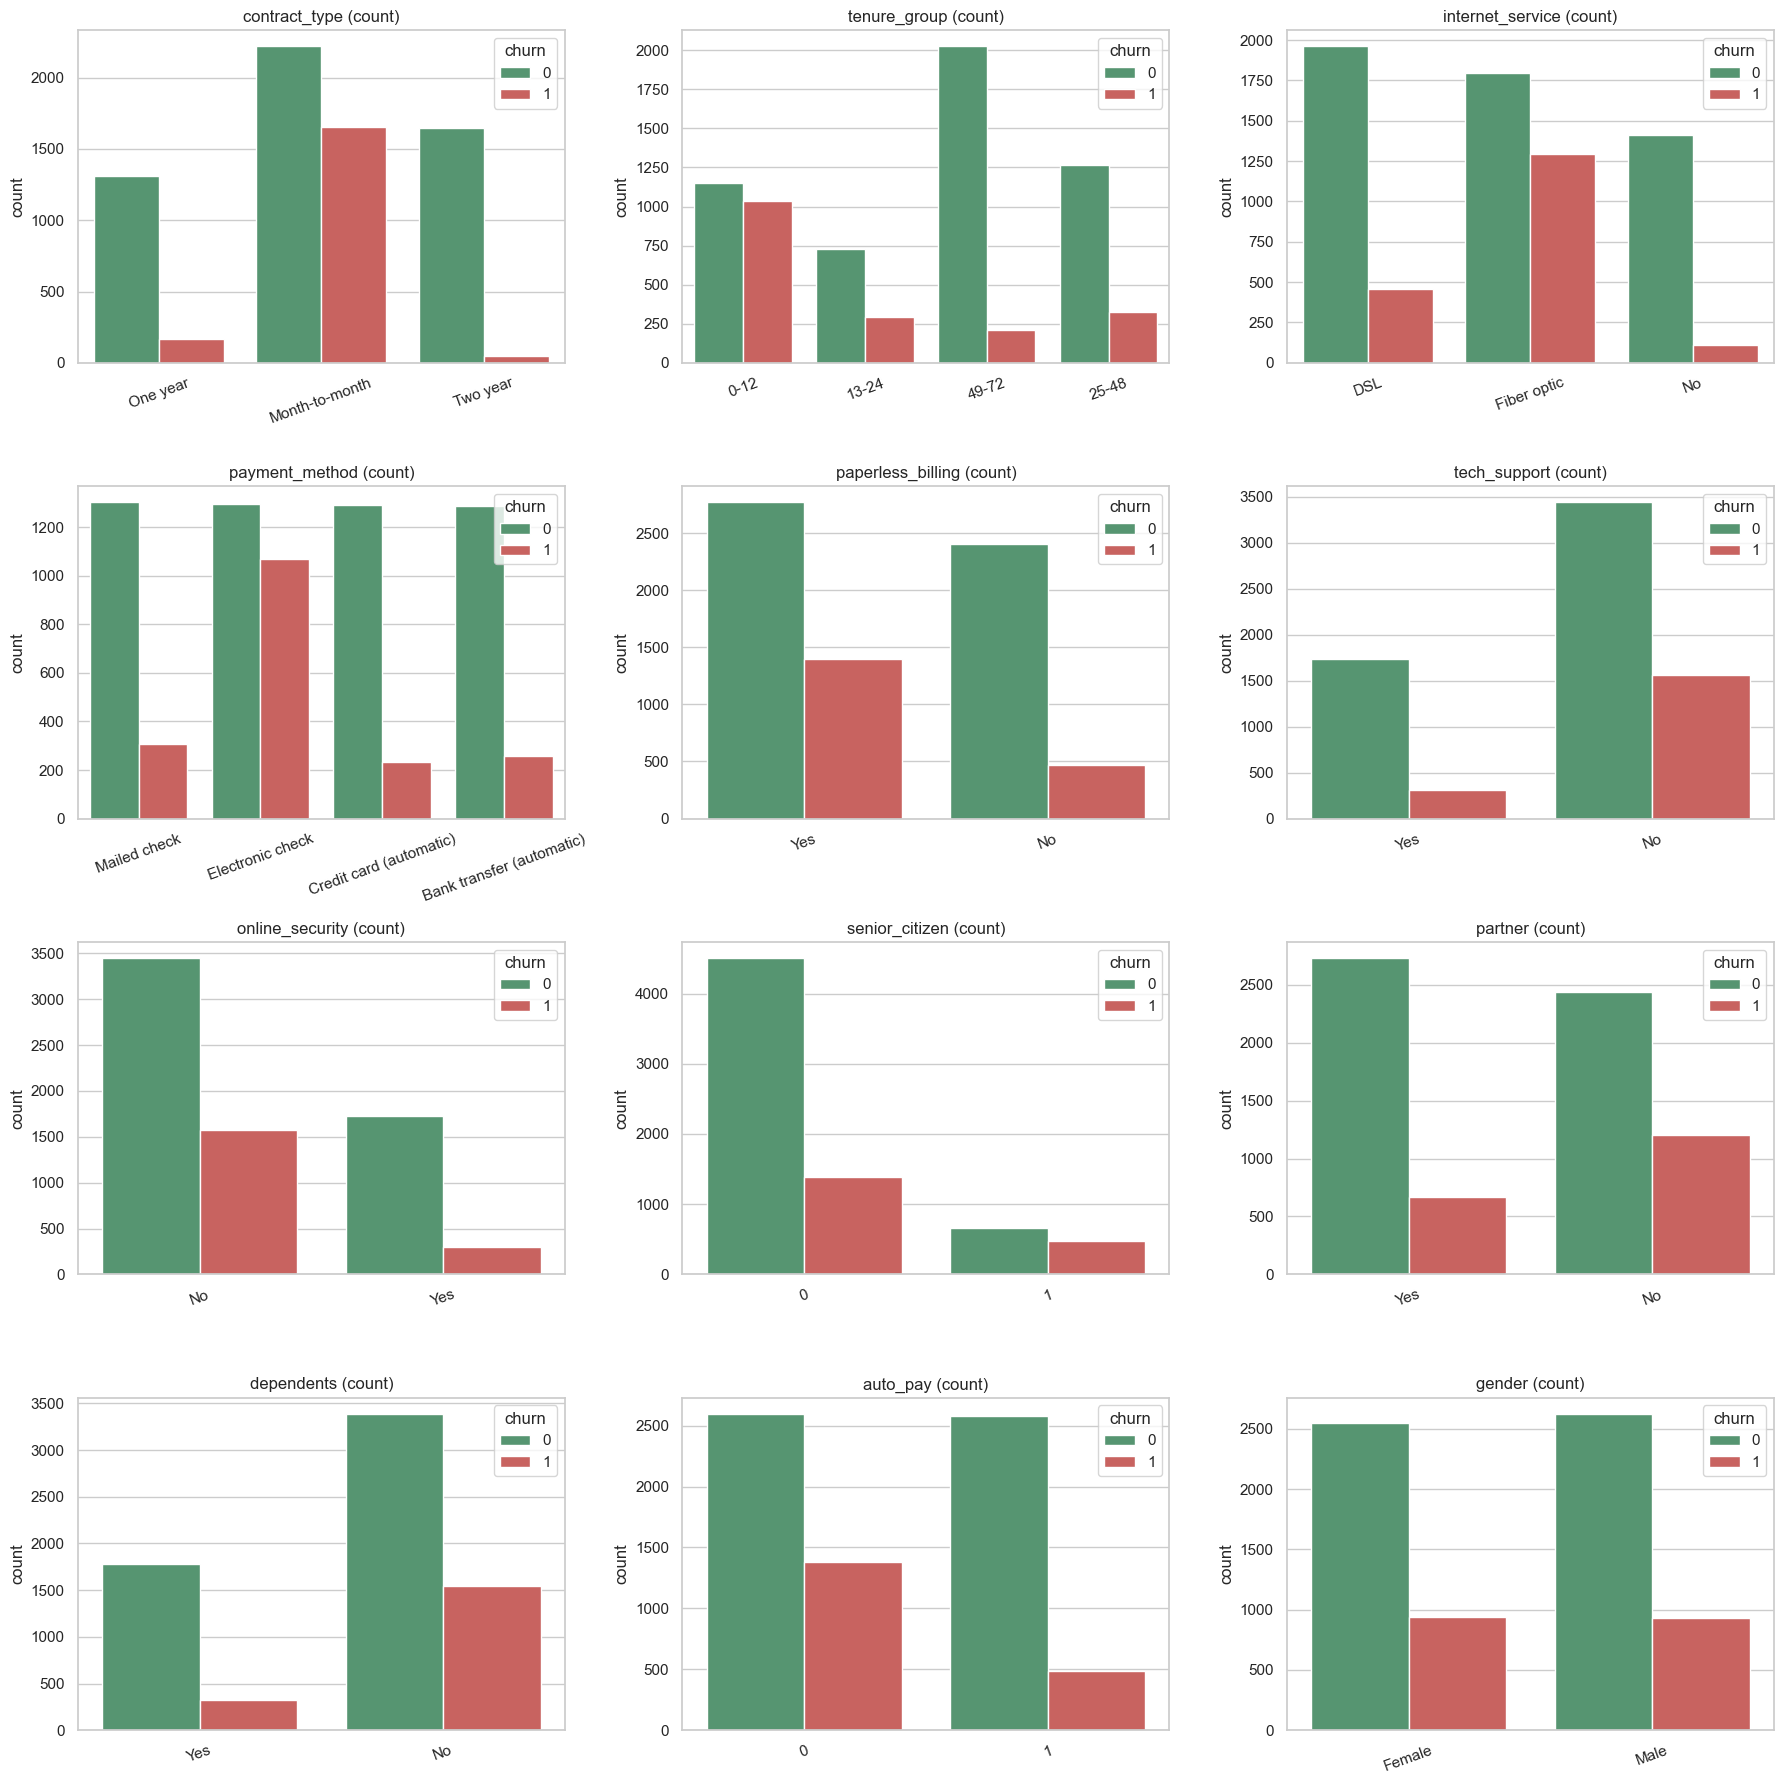

In [41]:
# Distribution of each categorical feature (count of customers per category)
fig, axes = plt.subplots(4, 3, figsize=(18, 18))
for ax, col in zip(axes.flatten(), cat_cols):
    sns.countplot(data=df, x=col, hue="churn", ax=ax, palette=["#4C9F70", "#D9534F"])
    ax.set_title(f"{col} (count)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

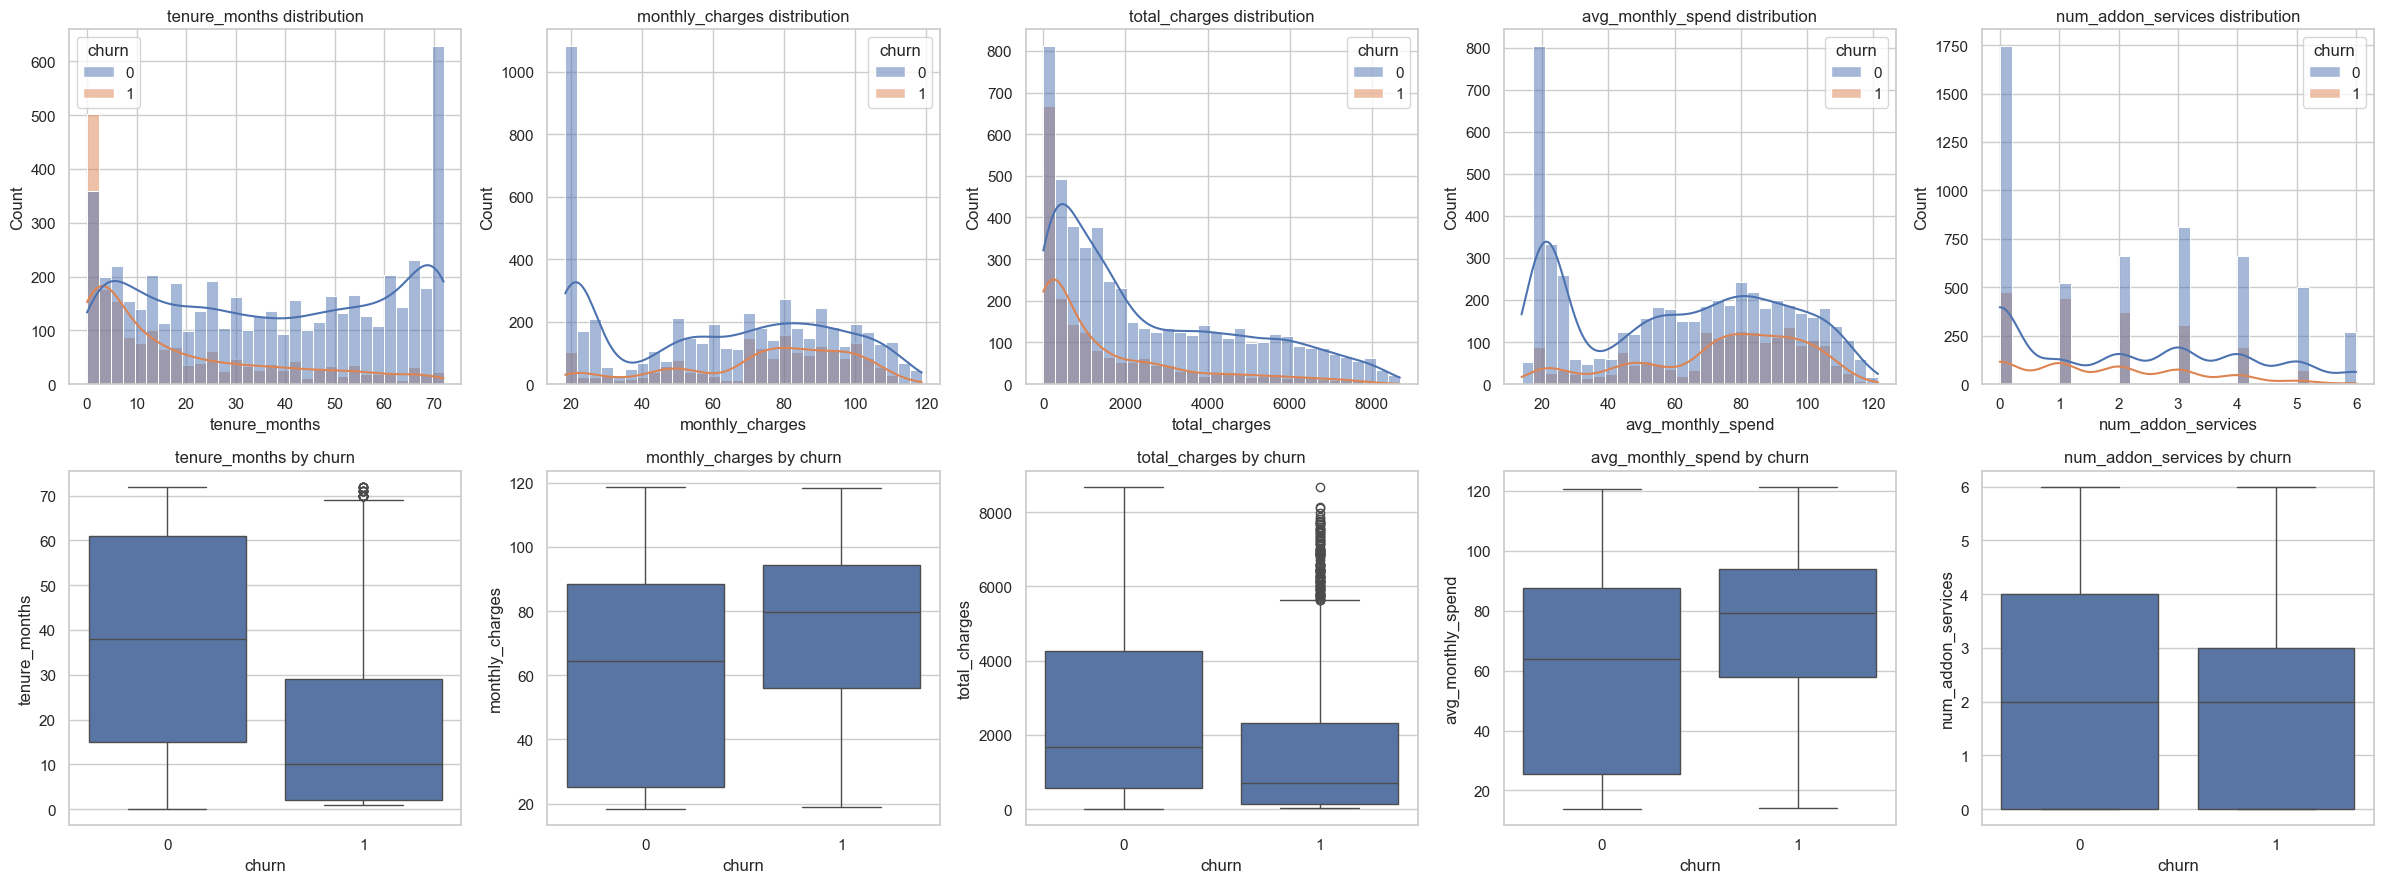

,tenure_months,monthly_charges,total_charges,avg_monthly_spend,num_addon_services
churn,,,,,
0,37.57,61.27,2549.91,61.27,2.14
1,17.98,74.44,1531.80,74.43,1.77


In [42]:
num_cols = ["tenure_months", "monthly_charges", "total_charges",
            "avg_monthly_spend", "num_addon_services"]

fig, axes = plt.subplots(2, 5, figsize=(24, 9))
for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue="churn", kde=True, ax=axes[0, i], bins=30)
    axes[0, i].set_title(f"{col} distribution")
    sns.boxplot(data=df, x="churn", y=col, ax=axes[1, i])
    axes[1, i].set_title(f"{col} by churn")
plt.tight_layout()
plt.show()

display(df.groupby("churn")[num_cols].mean().round(2))

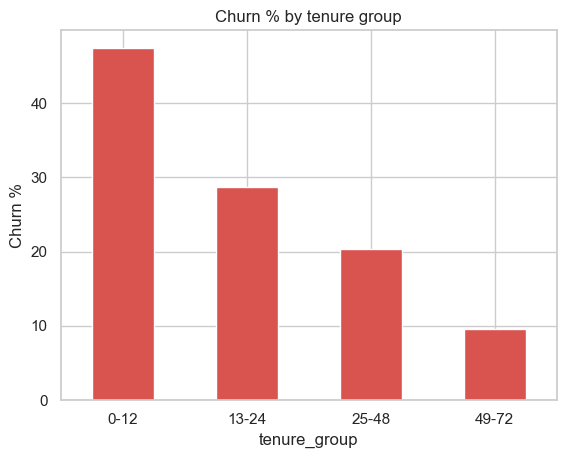

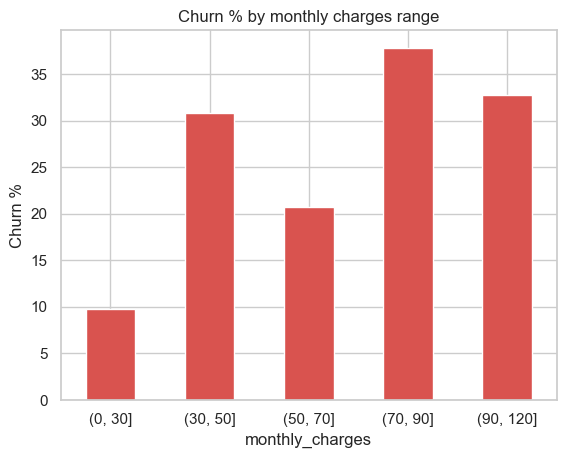

In [43]:
# Churn % by tenure group (ordered) and by monthly charges range
order = ["0-12", "13-24", "25-48", "49-72"]
df.groupby("tenure_group")["churn"].mean().reindex(order).mul(100).plot(kind="bar", color="#D9534F")
plt.title("Churn % by tenure group"); plt.ylabel("Churn %"); plt.xticks(rotation=0)
plt.show()

charges_bin = pd.cut(df["monthly_charges"], bins=[0, 30, 50, 70, 90, 120])
df.groupby(charges_bin, observed=True)["churn"].mean().mul(100).plot(kind="bar", color="#D9534F")
plt.title("Churn % by monthly charges range"); plt.ylabel("Churn %"); plt.xticks(rotation=0)
plt.show()

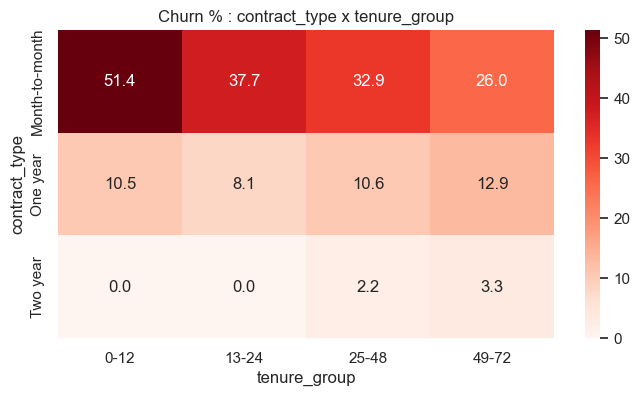

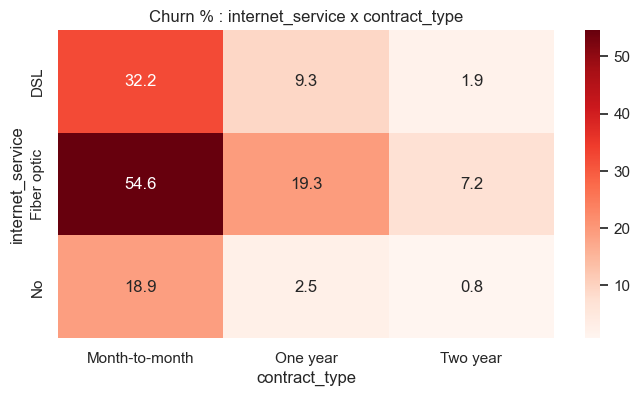

In [44]:
pivot = df.pivot_table(index="contract_type", columns="tenure_group",
                       values="churn", aggfunc="mean").mul(100).round(1)
plt.figure(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds")
plt.title("Churn % : contract_type x tenure_group")
plt.show()

pivot2 = df.pivot_table(index="internet_service", columns="contract_type",
                        values="churn", aggfunc="mean").mul(100).round(1)
plt.figure(figsize=(8, 4))
sns.heatmap(pivot2, annot=True, fmt=".1f", cmap="Reds")
plt.title("Churn % : internet_service x contract_type")
plt.show()

### Statistical tests (is the relationship with churn real, not chance?)

In [45]:
rows = []
for col in cat_cols:
    chi2, p, _, _ = chi2_contingency(pd.crosstab(df[col], df["churn"]))
    rows.append({"feature": col, "chi2": round(chi2, 1), "p_value": p, "significant": p < ALPHA})
display(pd.DataFrame(rows).sort_values("chi2", ascending=False))

rows = []
for col in num_cols:
    a = df.loc[df["churn"] == 1, col]
    b = df.loc[df["churn"] == 0, col]
    p = mannwhitneyu(a, b)[1]
    rows.append({"feature": col, "p_value": p, "significant": p < ALPHA,
                 "median_churn": a.median(), "median_stay": b.median()})
display(pd.DataFrame(rows))

,feature,chi2,p_value,significant
0,contract_type,1184.6,5.863038e-258,True
1,tenure_group,856.1,2.943770e-185,True
2,internet_service,732.3,9.571788e-160,True
3,payment_method,648.1,3.682355e-140,True
10,auto_pay,309.3,3.027873e-69,True
4,paperless_billing,258.3,4.073355e-58,True
6,online_security,205.6,1.232098e-46,True
5,tech_support,190.2,2.923567e-43,True
9,dependents,189.1,4.924922e-43,True
7,senior_citizen,159.4,1.510067e-36,True


,feature,p_value,significant,median_churn,median_stay
0,tenure_months,2.419636e-208,True,10.00,38.000
1,monthly_charges,3.311628e-54,True,79.65,64.425
2,total_charges,5.685034e-83,True,703.55,1679.525
3,avg_monthly_spend,2.086745e-54,True,79.31,63.980
4,num_addon_services,4.735235e-07,True,2.00,2.000


# Feature Engineering

In [46]:
# True if the customer has online security OR tech support (still Yes/No at this point)
df["has_protection"] = ((df["online_security"] == "Yes") | (df["tech_support"] == "Yes")).astype(int)
print("has_protection -> churn % when 1:", round(df.loc[df["has_protection"] == 1, "churn"].mean() * 100, 1),
      "| when 0:", round(df.loc[df["has_protection"] == 0, "churn"].mean() * 100, 1))

os.makedirs("/content/data/processed", exist_ok=True)
df.to_csv("/content/data/processed/clean_customers.csv", index=False)   # for the dashboard and report

has_protection -> churn % when 1: 17.1 | when 0: 33.4


# Correlation

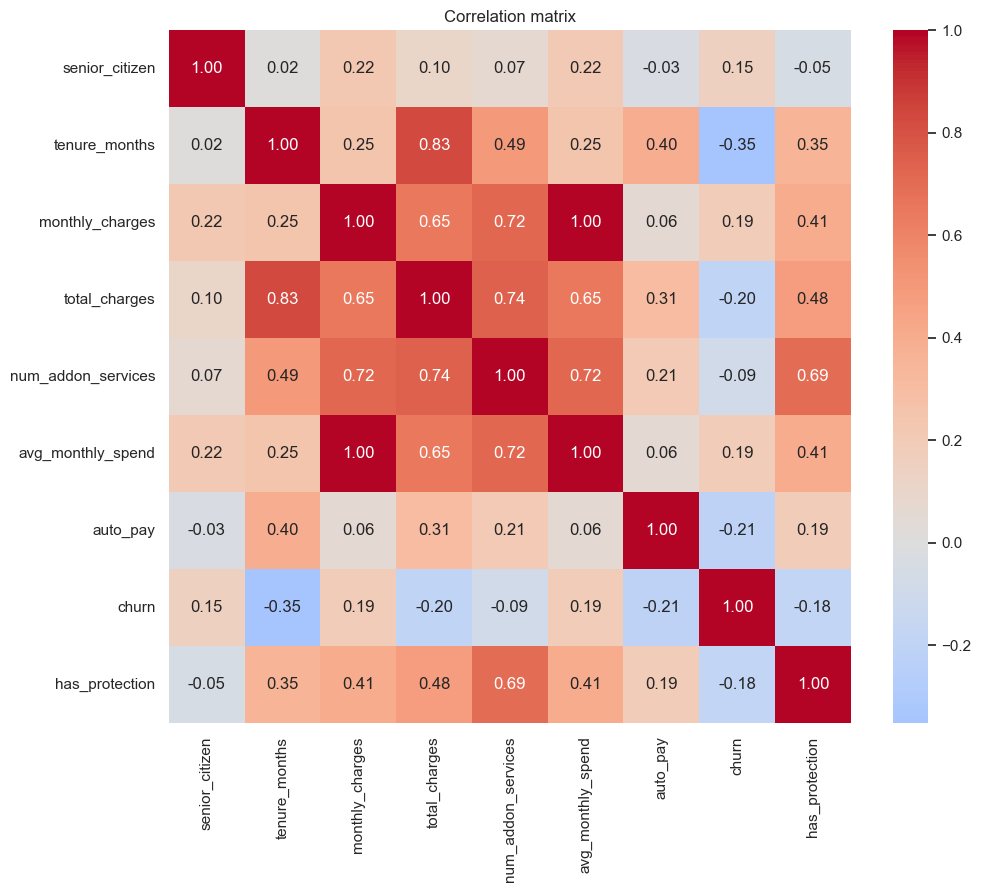

tenure_months        -0.352229
auto_pay             -0.209902
total_charges        -0.198324
has_protection       -0.182744
num_addon_services   -0.087698
senior_citizen        0.150889
avg_monthly_spend     0.192530
monthly_charges       0.193356
Name: churn, dtype: float64


In [47]:
# On the full cleaned data (descriptive EDA)
numeric_features = df.select_dtypes(include=[np.number]).columns.tolist()
corr = df[numeric_features].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

print(corr["churn"].drop("churn").sort_values())

# Split Data

In [48]:
drop_cols = ["customer_id", "avg_monthly_spend", "tenure_group"]
X = df.drop(columns=drop_cols + ["churn"]).copy()
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
print("Churn rate train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

(5634, 22) (1409, 22) (5634,) (1409,)
Churn rate train: 0.2654 | test: 0.2654


## Encoding & Scaling

### Binary columns: Yes/No and gender to 0/1

In [49]:
yes_no_cols = ["partner", "dependents", "phone_service", "multiple_lines",
               "online_security", "online_backup", "device_protection",
               "streaming_tv", "streaming_movies", "tech_support", "paperless_billing"]

for d in (X_train, X_test):
    for c in yes_no_cols:
        d[c] = d[c].map({"Yes": 1, "No": 0}).astype(int)
    d["gender"] = d["gender"].map({"Male": 1, "Female": 0}).astype(int)

### Drop weak features (p-value + strength, computed on the train set only)

In [50]:
model_num_cols = ["tenure_months", "monthly_charges", "total_charges", "num_addon_services"]

rows = []
for col in X_train.columns:
    if col in model_num_cols:
        a = X_train.loc[y_train == 1, col]
        b = X_train.loc[y_train == 0, col]
        p = mannwhitneyu(a, b)[1]
        strength = abs(X_train[col].corr(y_train))          # correlation
        method = "Mann-Whitney + Correlation"
    else:
        strength, p = cramers_v_and_p(X_train[col], y_train)  # Cramer's V
        method = "Chi-square + Cramer's V"
    rows.append({"feature": col, "method": method, "p_value": p, "strength": round(strength, 3)})

sel = pd.DataFrame(rows).sort_values("strength", ascending=False).reset_index(drop=True)
sel["keep"] = (sel["p_value"] < ALPHA) & (sel["strength"] >= MIN_STRENGTH)
display(sel)

weak = sel.loc[~sel["keep"], "feature"].tolist()
print("Dropped:", weak)
X_train = X_train.drop(columns=weak)
X_test = X_test.drop(columns=weak)

,feature,method,p_value,strength,keep
0,contract_type,Chi-square + Cramer's V,7.093651e-209,0.412,True
1,tenure_months,Mann-Whitney + Correlation,1.003036e-166,0.352,True
2,internet_service,Chi-square + Cramer's V,8.427817e-125,0.318,True
3,payment_method,Chi-square + Cramer's V,5.647611e-114,0.306,True
4,auto_pay,Chi-square + Cramer's V,2.011135e-57,0.213,True
5,total_charges,Mann-Whitney + Correlation,8.987968e-68,0.201,True
6,paperless_billing,Chi-square + Cramer's V,3.218295e-47,0.192,True
7,monthly_charges,Mann-Whitney + Correlation,1.522279e-41,0.189,True
8,has_protection,Chi-square + Cramer's V,3.351095e-44,0.186,True
9,tech_support,Chi-square + Cramer's V,1.368415e-37,0.171,True


Dropped: ['gender', 'phone_service']


### Numerical / Ordinal / One-Hot / Binary

In [51]:
numerical_cols = [c for c in model_num_cols if c in X_train.columns]
ordinal_cols = ["contract_type"] if USE_ORDINAL_CONTRACT and "contract_type" in X_train.columns else []
contract_order = [["Month-to-month", "One year", "Two year"]]
onehot_cols = [c for c in X_train.select_dtypes(include="object").columns if c not in ordinal_cols]
binary_cols = [c for c in X_train.columns if c not in numerical_cols + ordinal_cols + onehot_cols]

print("Numerical:", numerical_cols)
print("Ordinal  :", ordinal_cols)
print("One-Hot  :", onehot_cols)
print("Binary   :", binary_cols)
assert len(numerical_cols) + len(ordinal_cols) + len(onehot_cols) + len(binary_cols) == X_train.shape[1]

transformers = [
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), onehot_cols),
    ("bin", "passthrough", binary_cols),          # already 0/1, left as is
]
if ordinal_cols:
    transformers.insert(1, ("ord", OrdinalEncoder(categories=contract_order), ordinal_cols))
preprocessor = ColumnTransformer(transformers)

X_train_enc = pd.DataFrame(preprocessor.fit_transform(X_train),     # fit on train only
                           columns=preprocessor.get_feature_names_out(), index=X_train.index)
X_test_enc = pd.DataFrame(preprocessor.transform(X_test),           # transform only
                          columns=preprocessor.get_feature_names_out(), index=X_test.index)

print("Train:", X_train_enc.shape, "| Test:", X_test_enc.shape)
display(X_train_enc.head())

Numerical: ['tenure_months', 'monthly_charges', 'total_charges', 'num_addon_services']
Ordinal  : ['contract_type']
One-Hot  : ['internet_service', 'payment_method']
Binary   : ['senior_citizen', 'partner', 'dependents', 'multiple_lines', 'online_security', 'online_backup', 'device_protection', 'streaming_tv', 'streaming_movies', 'tech_support', 'paperless_billing', 'auto_pay', 'has_protection']
Train: (5634, 23) | Test: (1409, 23)


,num__tenure_months,num__monthly_charges,num__total_charges,num__num_addon_services,ord__contract_type,cat__internet_service_Fiber optic,cat__internet_service_No,cat__payment_method_Credit card (automatic),cat__payment_method_Electronic check,cat__payment_method_Mailed check,bin__senior_citizen,bin__partner,bin__dependents,bin__multiple_lines,bin__online_security,bin__online_backup,bin__device_protection,bin__streaming_tv,bin__streaming_movies,bin__tech_support,bin__paperless_billing,bin__auto_pay,bin__has_protection
3793,1.124891,0.968250,1.398565,0.518023,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0
3192,-0.827880,-1.521717,-0.913119,-1.113055,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4922,-1.234707,0.513560,-0.946146,-0.025670,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
3926,0.026457,0.323690,0.071090,1.061715,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0
3859,-0.746514,0.698434,-0.495126,-0.025670,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0


In [52]:
X_train_enc.assign(churn=y_train.values).to_csv("/content/data/processed/train_encoded.csv", index=False)
X_test_enc.assign(churn=y_test.values).to_csv("/content/data/processed/test_encoded.csv", index=False)
print("Saved: clean_customers.csv, train_encoded.csv, test_encoded.csv")

Saved: clean_customers.csv, train_encoded.csv, test_encoded.csv


,check,passed
0,Train/Test have same columns,True
1,No nulls in train,True
2,No nulls in test,True
3,All columns numeric,True
4,Rows match labels (train),True
5,Rows match labels (test),True
6,Binary columns only 0/1,True
7,Scaled columns mean ~ 0,True
8,Scaled columns std ~ 1,True


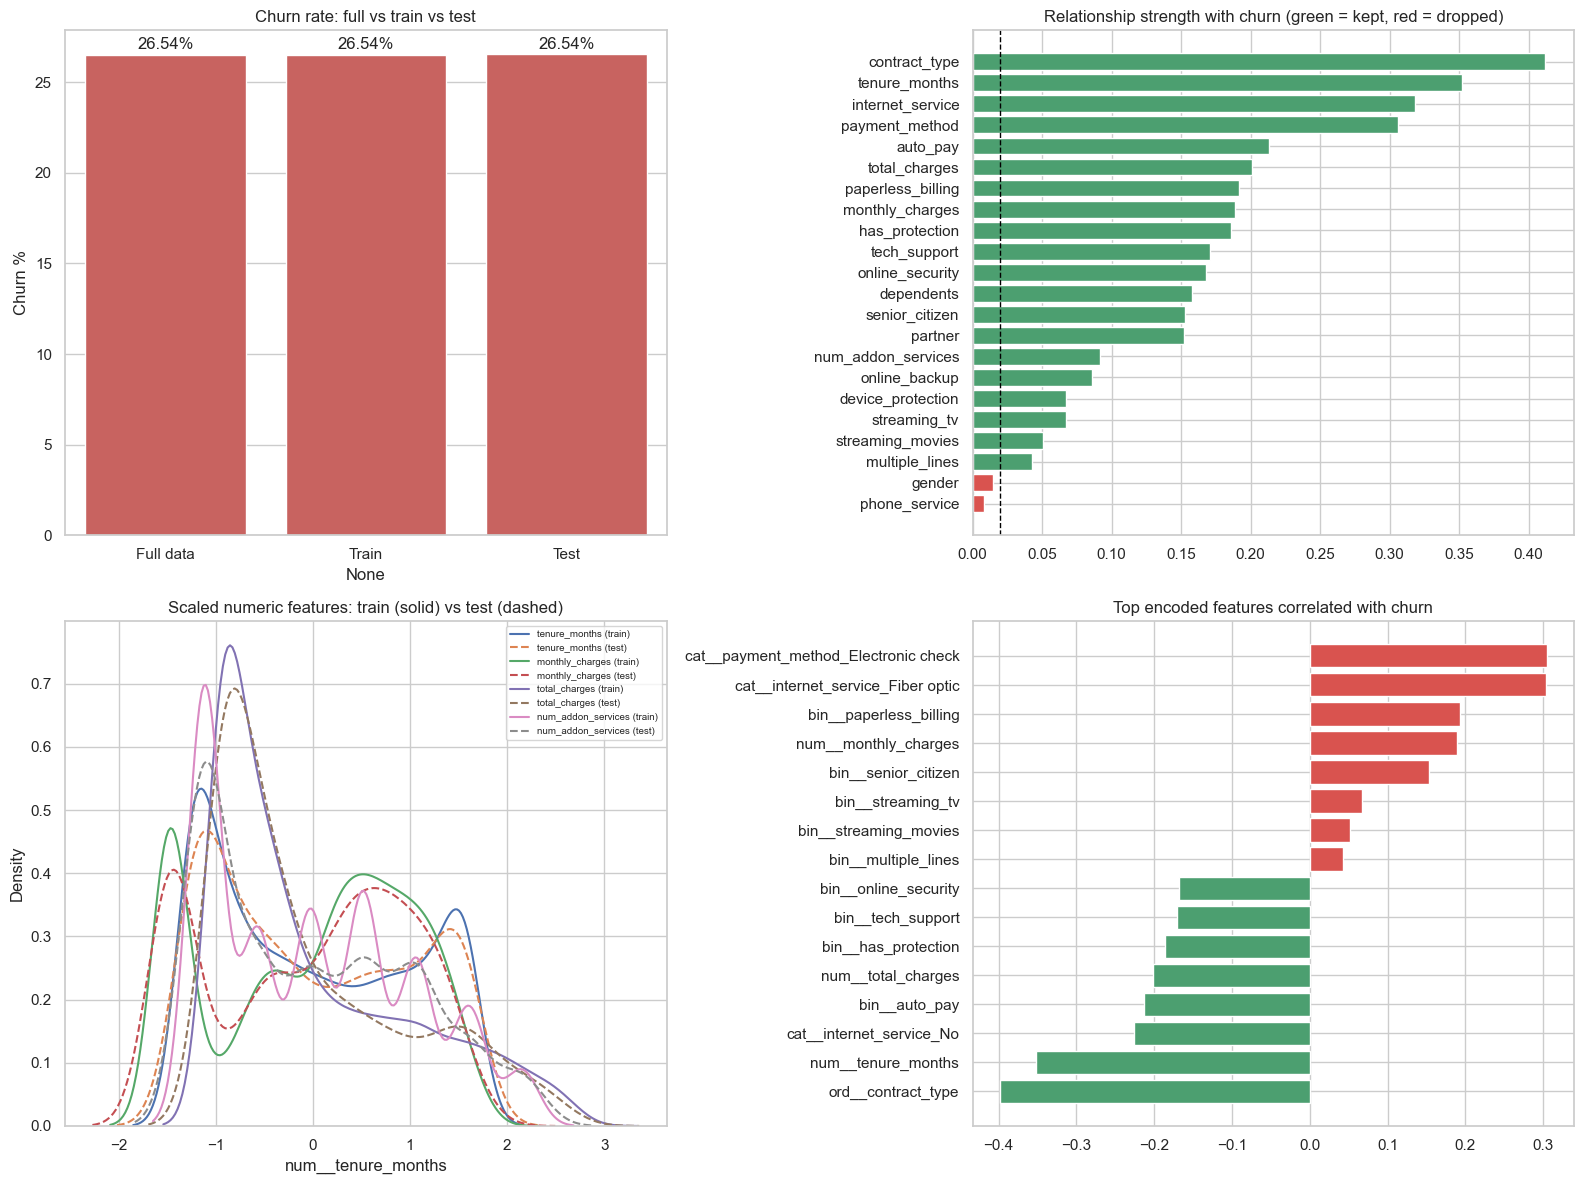

In [53]:
# %% ================= Final Validation: sanity checks + plots =================
# 1) Sanity checks
checks = {
    "Train/Test have same columns": list(X_train_enc.columns) == list(X_test_enc.columns),
    "No nulls in train": int(X_train_enc.isnull().sum().sum()) == 0,
    "No nulls in test": int(X_test_enc.isnull().sum().sum()) == 0,
    "All columns numeric": all(np.issubdtype(t, np.number) for t in X_train_enc.dtypes),
    "Rows match labels (train)": len(X_train_enc) == len(y_train),
    "Rows match labels (test)": len(X_test_enc) == len(y_test),
    "Binary columns only 0/1": all(set(X_train_enc[f"bin__{c}"].unique()) <= {0, 1} for c in binary_cols),
    "Scaled columns mean ~ 0": bool(np.allclose(X_train_enc[[f"num__{c}" for c in numerical_cols]].mean(), 0, atol=1e-6)),
    "Scaled columns std ~ 1": bool(np.allclose(X_train_enc[[f"num__{c}" for c in numerical_cols]].std(ddof=0), 1, atol=1e-6)),
}
display(pd.DataFrame({"check": checks.keys(), "passed": checks.values()}))
assert all(checks.values()), "A check failed, see the table above"

# 2) Plots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# a) churn rate in train vs test (stratify worked)
rates = pd.Series({"Full data": y.mean() * 100, "Train": y_train.mean() * 100, "Test": y_test.mean() * 100})
sns.barplot(x=rates.index, y=rates.values, ax=axes[0, 0], color="#D9534F")
for i, v in enumerate(rates.values):
    axes[0, 0].text(i, v + 0.3, f"{v:.2f}%", ha="center")
axes[0, 0].set_title("Churn rate: full vs train vs test"); axes[0, 0].set_ylabel("Churn %")

# b) feature strength, kept vs dropped
colors = ["#4C9F70" if k else "#D9534F" for k in sel["keep"]]
axes[0, 1].barh(sel["feature"][::-1], sel["strength"][::-1], color=colors[::-1])
axes[0, 1].axvline(MIN_STRENGTH, color="black", linestyle="--", linewidth=1)
axes[0, 1].set_title("Relationship strength with churn (green = kept, red = dropped)")

# c) scaled numeric features: train vs test distributions
for c in numerical_cols:
    sns.kdeplot(X_train_enc[f"num__{c}"], ax=axes[1, 0], label=f"{c} (train)")
    sns.kdeplot(X_test_enc[f"num__{c}"], ax=axes[1, 0], linestyle="--", label=f"{c} (test)")
axes[1, 0].set_title("Scaled numeric features: train (solid) vs test (dashed)")
axes[1, 0].legend(fontsize=7)

# d) correlation of every encoded feature with churn
enc_corr = X_train_enc.corrwith(y_train).sort_values()
top = pd.concat([enc_corr.head(8), enc_corr.tail(8)])
axes[1, 1].barh(top.index, top.values, color=["#4C9F70" if v < 0 else "#D9534F" for v in top.values])
axes[1, 1].set_title("Top encoded features correlated with churn")

plt.tight_layout()
plt.show()

# Hameed

In [55]:
print("hh")

hh
